# B2 — Khám phá Dữ liệu (EDA), Làm sạch, Chống Rò rỉ & Chia Tập Dữ liệu

**Mục tiêu của Bước 2 (B2):**
1. Đọc toàn bộ 3 tập dữ liệu gốc (`train.csv`, `test.csv`, `overall_data.csv`).
2. **Kiểm toán & Chống rò rỉ dữ liệu (Zero Data Leakage):** loại bỏ câu ngắn/rỗng, câu mâu thuẫn nhãn, câu trùng lặp nội bộ và mọi câu trùng khớp với tập `test.csv`.
3. Tách tập train sạch thành **`train_pool.csv` (90%)** + **`val.csv` (10%, Stratified cố định)** và sinh **7 tập con (`train_subset1..7.csv`, 10.000 mẫu/tập)** cho Run 1.
4. **Xuất 5 biểu đồ EDA chuẩn báo cáo (300 DPI `.png` + `.pdf`)** lưu tại `workspace_outputs/figures/B2_eda/`:
   - `B2_01_phan_bo_lop_esg`: Phân bố 4 lớp ESG trên `Train Pool`, `Validation`, `Test`.
   - `B2_02_phan_bo_do_dai_van_ban`: Phân bố độ dài câu (số từ) + phân vị 95%/99% + ngưỡng `max_length=256`.
   - `B2_03_tu_khoa_dac_trung_4_lop`: Top-12 từ/cụm từ đặc trưng (TF-IDF 1–2 gram) của 4 lớp.
   - `B2_04_wordcloud_4_lop_esg`: 4 WordCloud tiếng Việt theo chủ đề ESG.
   - `B2_05_kiem_toan_lam_sach_du_lieu`: Báo cáo kiểm toán dữ liệu trước & sau làm sạch.

In [1]:
# Bước 2.1: Khởi tạo đường dẫn, cấu hình và cố định seed ngẫu nhiên
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    PipelineConfig,
    ensure_directories,
    set_global_seed,
    get_figure_dir,
    RAW_TRAIN_PATH,
    RAW_TEST_PATH,
    RAW_UNLABELED_PATH,
    PROCESSED_DATA_DIR,
    SUBSETS_DIR,
    METRICS_DIR,
    ID2LABEL,
)
from src.preprocessing import (
    VietnameseESGPreprocessor,
    audit_and_deduplicate,
    split_train_val_and_subsets,
)
from src.viz_utils import (
    plot_class_distribution_comparison,
    plot_text_length_distribution,
    plot_top_keywords_by_class,
    plot_wordclouds_by_class,
    plot_data_cleaning_audit,
)

ensure_directories()
cfg = PipelineConfig(hardware_mode="balanced", model_preset="full_7")
set_global_seed(cfg.seed)
FIG_DIR = get_figure_dir("B2")

print(cfg.summary())
print(f"\nNơi lưu biểu đồ Bước B2: {FIG_DIR}")

=== CẤU HÌNH HỆ THỐNG VI-ESG-BERT ===
- Chế độ phần cứng : balanced (train_bs=16 x accum=2, bf16=True, grad_ckpt=False, nghỉ=15s)
- Gói mô hình      : full_7 (7 mô hình: phobert-base, distilbert-base-multilingual-cased, bert-base-multilingual-cased, roberta-base, electra-base-vn, visobert, videberta-base)
- Công tắc an toàn : skip_if_done=True | ablation_baseline=True
- Siêu tham số     : seed=42 | max_length=256 | lr=2e-05 | metric=f1_macro
- Thư mục biểu đồ  : D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures (DPI=300, PDF=True)

Nơi lưu biểu đồ Bước B2: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B2_eda


In [2]:
# Bước 2.2: Đọc dữ liệu gốc và xem nhanh cấu trúc 3 tập dữ liệu
raw_train = pd.read_csv(RAW_TRAIN_PATH)
raw_test = pd.read_csv(RAW_TEST_PATH)
raw_unlabeled = pd.read_csv(RAW_UNLABELED_PATH)

print(f"Train gốc     : {raw_train.shape} | Cột: {list(raw_train.columns)} | Thiếu: {raw_train.isna().sum().to_dict()}")
print(f"Test gốc      : {raw_test.shape}  | Cột: {list(raw_test.columns)} | Thiếu: {raw_test.isna().sum().to_dict()}")
print(f"Unlabeled gốc : {raw_unlabeled.shape} | Cột: {list(raw_unlabeled.columns)} | Thiếu: {raw_unlabeled.isna().sum().to_dict()}")

display(raw_train.head(5))

Train gốc     : (27366, 2) | Cột: ['vi_text', 'labels'] | Thiếu: {'vi_text': 0, 'labels': 0}
Test gốc      : (3000, 2)  | Cột: ['vi_text', 'labels'] | Thiếu: {'vi_text': 0, 'labels': 0}
Unlabeled gốc : (54490, 1) | Cột: ['vi_text'] | Thiếu: {'vi_text': 0}


,vi_text,labels
0,Thêm dấu phẩy sau trên 700 nghìn tỷ đồng vốn đ...,0
1,Lựa chọn cổ phiếu niêm yết có chỉ số PB cao đư...,0
2,Chính sách bảo hiểm nông nghiệp là tia hy vọng...,2
3,Ngoài ra Vingroup cam kết phát triển các dự án...,2
4,Diện tích trồng cà gai leo tại địa phương là k...,1


In [3]:
# Bước 2.3: Chạy Kiểm toán chất lượng, Làm sạch Unicode NFC & Chống rò rỉ dữ liệu
train_clean, test_clean, unlabeled_clean, audit_report = audit_and_deduplicate(
    train_df=raw_train,
    test_df=raw_test,
    unlabeled_df=raw_unlabeled,
    text_col=cfg.text_column,
    label_col=cfg.label_column,
    min_words=cfg.min_word_count,
)

print("=== BÁO CÁO KIỂM TOÁN DỮ LIỆU (ZERO DATA LEAKAGE) ===")
for k, v in audit_report.items():
    print(f"  {k:<40}: {v:,}")

# Lưu báo cáo kiểm toán ra JSON phục vụ viết bảng trong báo cáo
audit_path = METRICS_DIR / "B2_data_audit_report.json"
with open(audit_path, "w", encoding="utf-8") as f:
    json.dump(audit_report, f, ensure_ascii=False, indent=2)
print(f"\n[Đã lưu] {audit_path}")

=== BÁO CÁO KIỂM TOÁN DỮ LIỆU (ZERO DATA LEAKAGE) ===
  train_raw_rows                          : 27,366
  test_raw_rows                           : 3,000
  unlabeled_raw_rows                      : 54,490
  test_unique_keys                        : 3,000
  test_internal_duplicates                : 0
  train_removed_short_or_empty            : 0
  train_short_under_min_words             : 0
  train_removed_label_conflicts           : 0
  train_removed_internal_duplicates       : 1
  train_removed_test_leakage              : 0
  train_clean_rows                        : 27,365
  unlabeled_removed_short_or_empty        : 0
  unlabeled_removed_internal_duplicates   : 3
  unlabeled_removed_test_leakage          : 0
  unlabeled_removed_train_overlap         : 0
  unlabeled_clean_rows                    : 54,487
  test_clean_rows                         : 3,000

[Đã lưu] D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\metrics\B2_data_audit_report.json


In [4]:
# Bước 2.4: Tách Train Pool (90%) + Validation cố định (10%, Stratified) & tạo 7 Subsets cho Run 1
train_pool_df, val_df, subsets = split_train_val_and_subsets(
    train_clean_df=train_clean,
    val_ratio=cfg.val_ratio,
    n_subsets=7,
    subset_size=cfg.subset_size,
    seed=cfg.seed,
    label_col=cfg.label_column,
)

# Lưu toàn bộ dữ liệu sạch vào workspace_outputs/processed_data/
train_pool_df.to_csv(PROCESSED_DATA_DIR / "train_pool.csv", index=False, encoding="utf-8-sig")
val_df.to_csv(PROCESSED_DATA_DIR / "val.csv", index=False, encoding="utf-8-sig")
test_clean.to_csv(PROCESSED_DATA_DIR / "test_clean.csv", index=False, encoding="utf-8-sig")
unlabeled_clean.to_csv(PROCESSED_DATA_DIR / "unlabeled_clean.csv", index=False, encoding="utf-8-sig")

for i, sub_df in enumerate(subsets, start=1):
    sub_path = SUBSETS_DIR / f"train_subset{i}.csv"
    sub_df.to_csv(sub_path, index=False, encoding="utf-8-sig")

print("=== TỔNG KẾT CÁC TẬP DỮ LIỆU ĐÃ LƯU ===")
print(f"- train_pool.csv      : {len(train_pool_df):,} mẫu")
print(f"- val.csv (cố định)   : {len(val_df):,} mẫu")
print(f"- test_clean.csv      : {len(test_clean):,} mẫu (Hold-out khóa kín)")
print(f"- unlabeled_clean.csv : {len(unlabeled_clean):,} mẫu")
print(f"- 7 subsets Run 1     : {len(subsets)} file x {len(subsets[0]):,} mẫu -> {SUBSETS_DIR}")

=== TỔNG KẾT CÁC TẬP DỮ LIỆU ĐÃ LƯU ===
- train_pool.csv      : 24,628 mẫu
- val.csv (cố định)   : 2,737 mẫu
- test_clean.csv      : 3,000 mẫu (Hold-out khóa kín)
- unlabeled_clean.csv : 54,487 mẫu
- 7 subsets Run 1     : 7 file x 10,000 mẫu -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\processed_data\subsets


[Đã lưu biểu đồ] B2_01_phan_bo_lop_esg.png, B2_01_phan_bo_lop_esg.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B2_eda


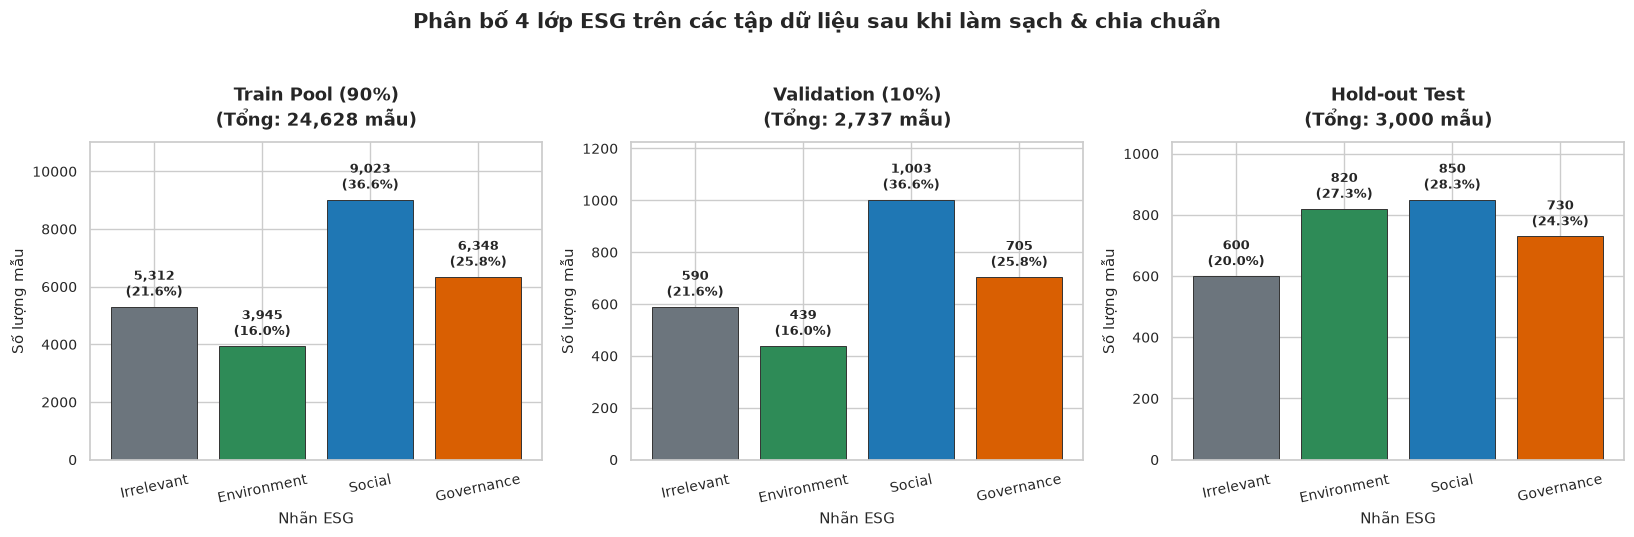

In [5]:
# Bước 2.5 — Biểu đồ B2.1: So sánh phân bố 4 lớp ESG trên Train Pool, Validation và Test
fig1 = plot_class_distribution_comparison(
    datasets={
        "Train Pool (90%)": train_pool_df,
        "Validation (10%)": val_df,
        "Hold-out Test": test_clean,
    },
    label_col=cfg.label_column,
    save_dir=FIG_DIR,
    filename_stem="B2_01_phan_bo_lop_esg",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

[Đã lưu biểu đồ] B2_02_phan_bo_do_dai_van_ban.png, B2_02_phan_bo_do_dai_van_ban.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B2_eda


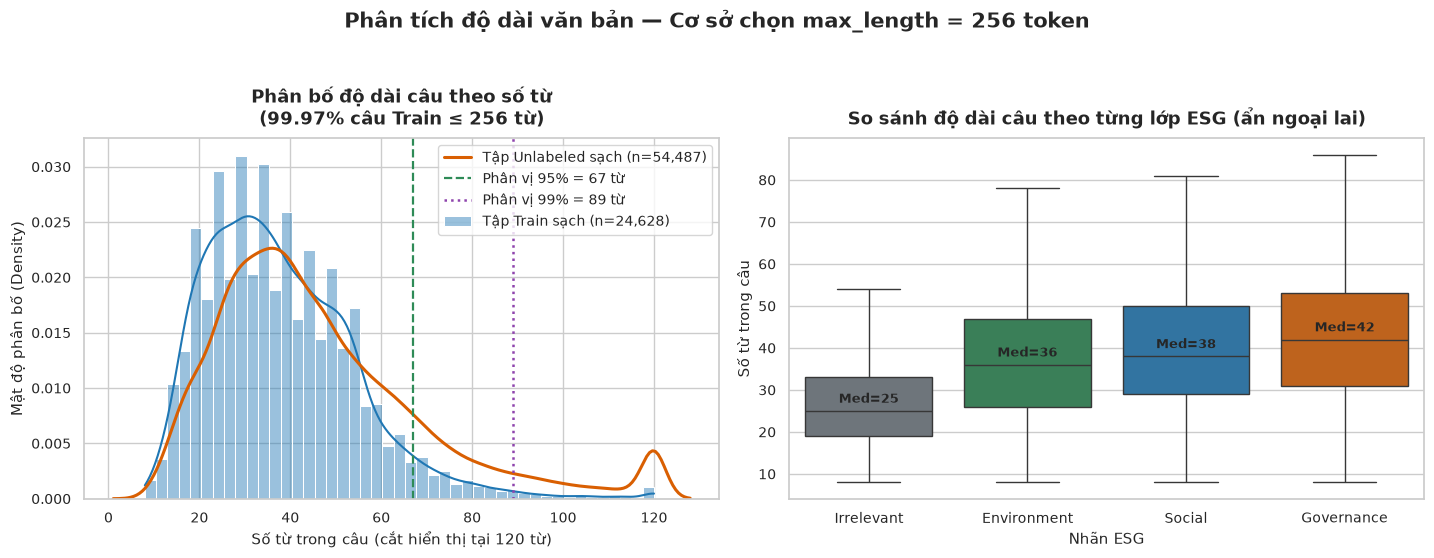

In [6]:
# Bước 2.6 — Biểu đồ B2.2: Phân bố độ dài câu (cơ sở chọn max_length = 256)
fig2 = plot_text_length_distribution(
    train_df=train_pool_df,
    unlabeled_df=unlabeled_clean,
    text_col=cfg.text_column,
    label_col=cfg.label_column,
    max_length_ref=cfg.max_length,
    save_dir=FIG_DIR,
    filename_stem="B2_02_phan_bo_do_dai_van_ban",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

[Đã lưu biểu đồ] B2_03_tu_khoa_dac_trung_4_lop.png, B2_03_tu_khoa_dac_trung_4_lop.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B2_eda


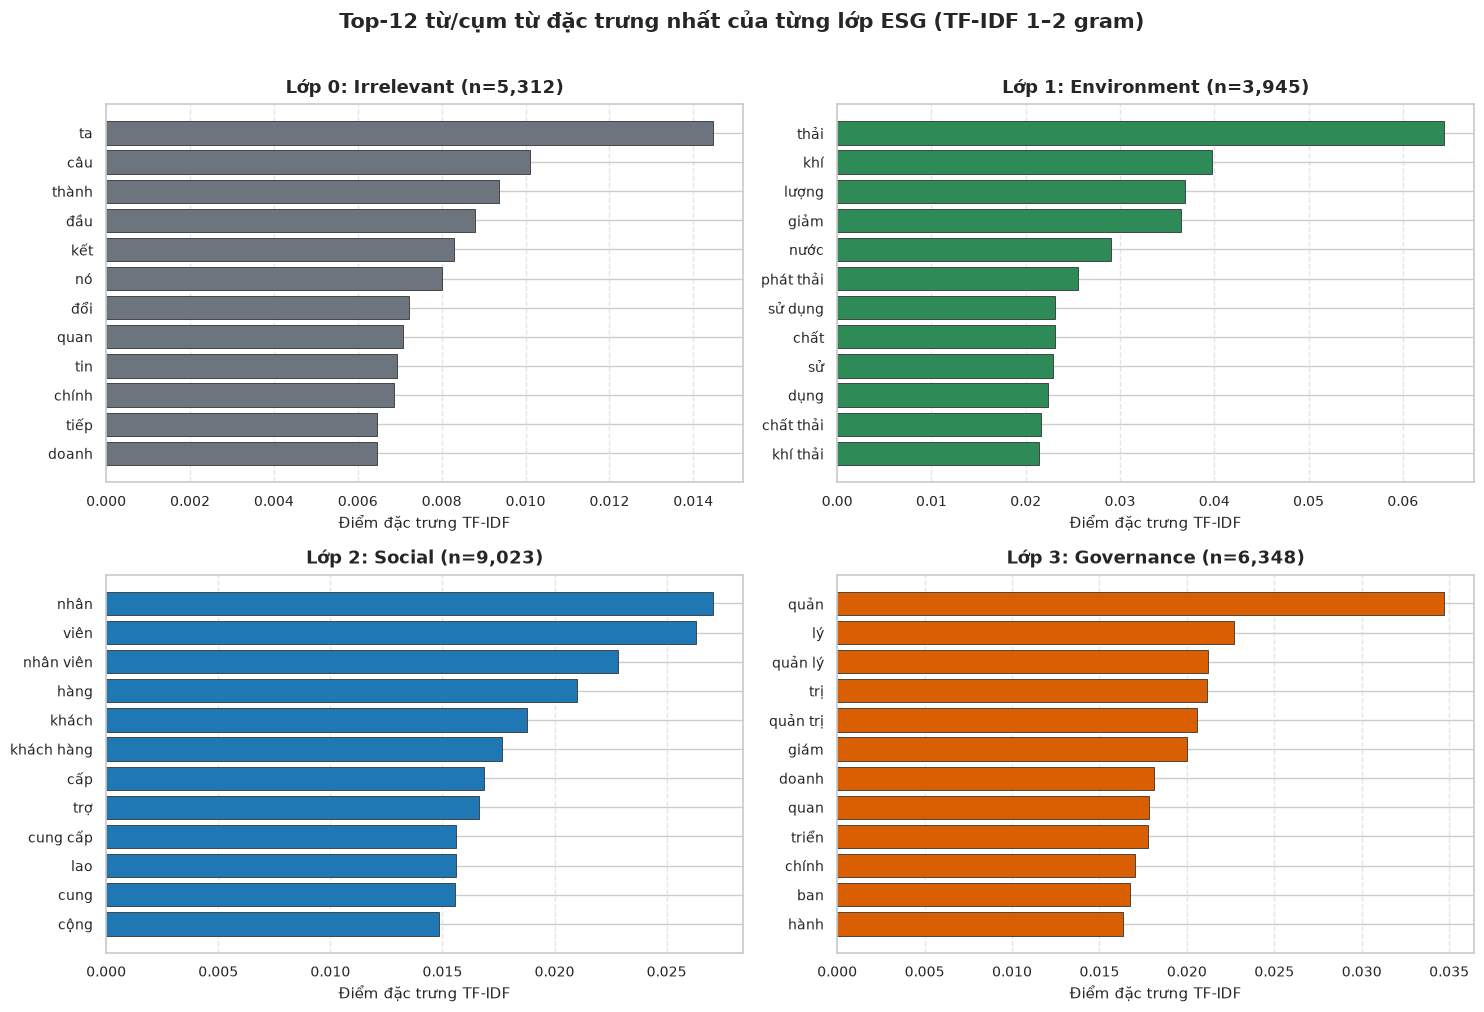

[Đã lưu biểu đồ] B2_04_wordcloud_4_lop_esg.png, B2_04_wordcloud_4_lop_esg.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B2_eda


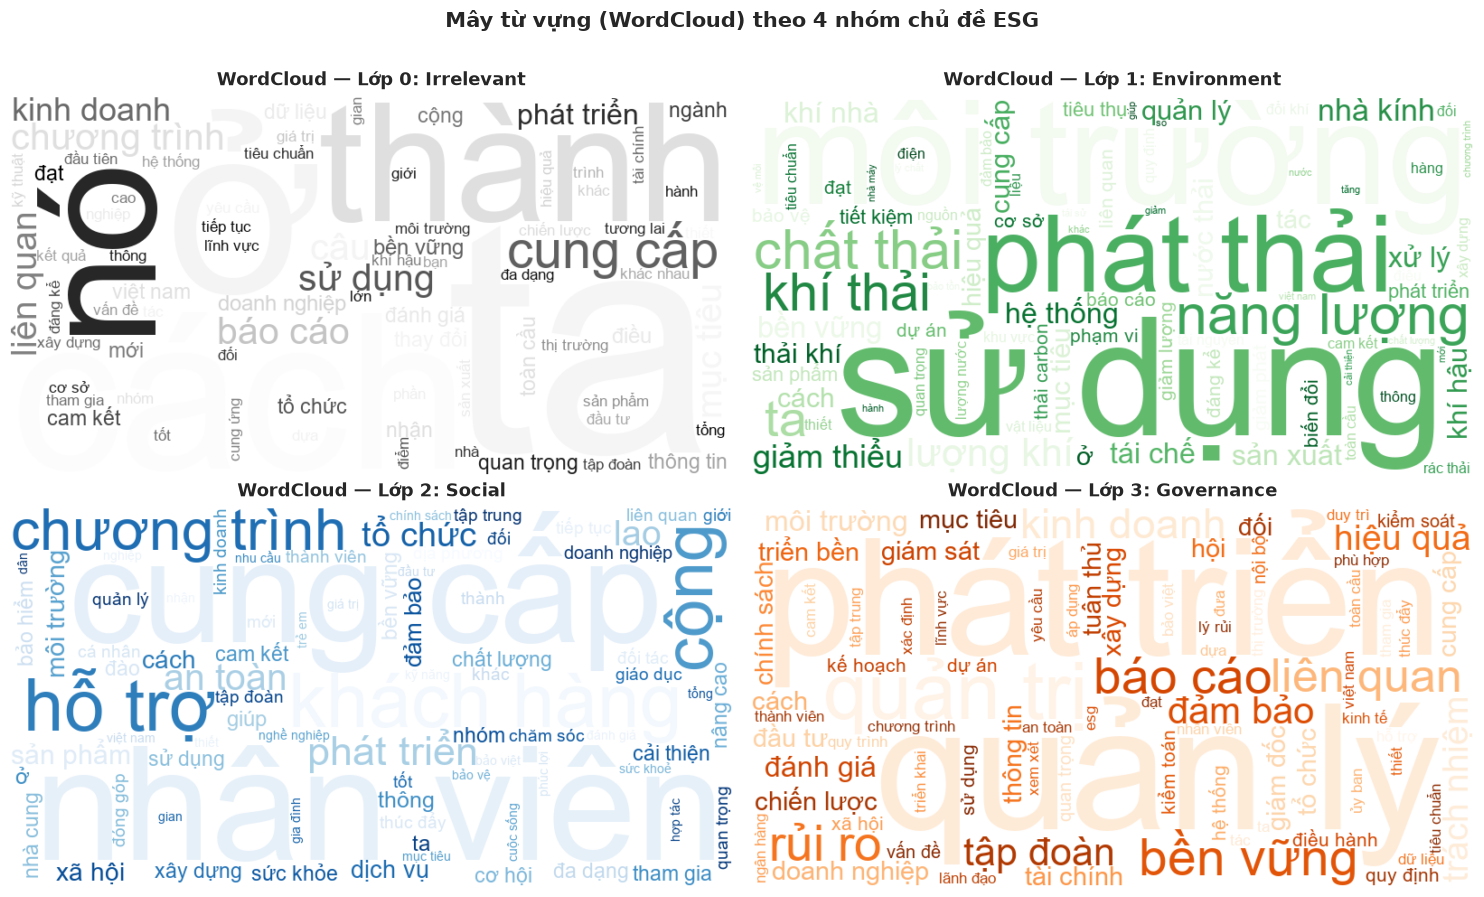

In [7]:
# Bước 2.7 — Biểu đồ B2.3 & B2.4: Từ khóa đặc trưng TF-IDF & WordCloud cho 4 lớp ESG
fig3 = plot_top_keywords_by_class(
    df=train_pool_df,
    text_col=cfg.text_column,
    label_col=cfg.label_column,
    top_n=12,
    save_dir=FIG_DIR,
    filename_stem="B2_03_tu_khoa_dac_trung_4_lop",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

fig4 = plot_wordclouds_by_class(
    df=train_pool_df,
    text_col=cfg.text_column,
    label_col=cfg.label_column,
    save_dir=FIG_DIR,
    filename_stem="B2_04_wordcloud_4_lop_esg",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
if fig4 is not None:
    plt.show()

[Đã lưu biểu đồ] B2_05_kiem_toan_lam_sach_du_lieu.png, B2_05_kiem_toan_lam_sach_du_lieu.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B2_eda


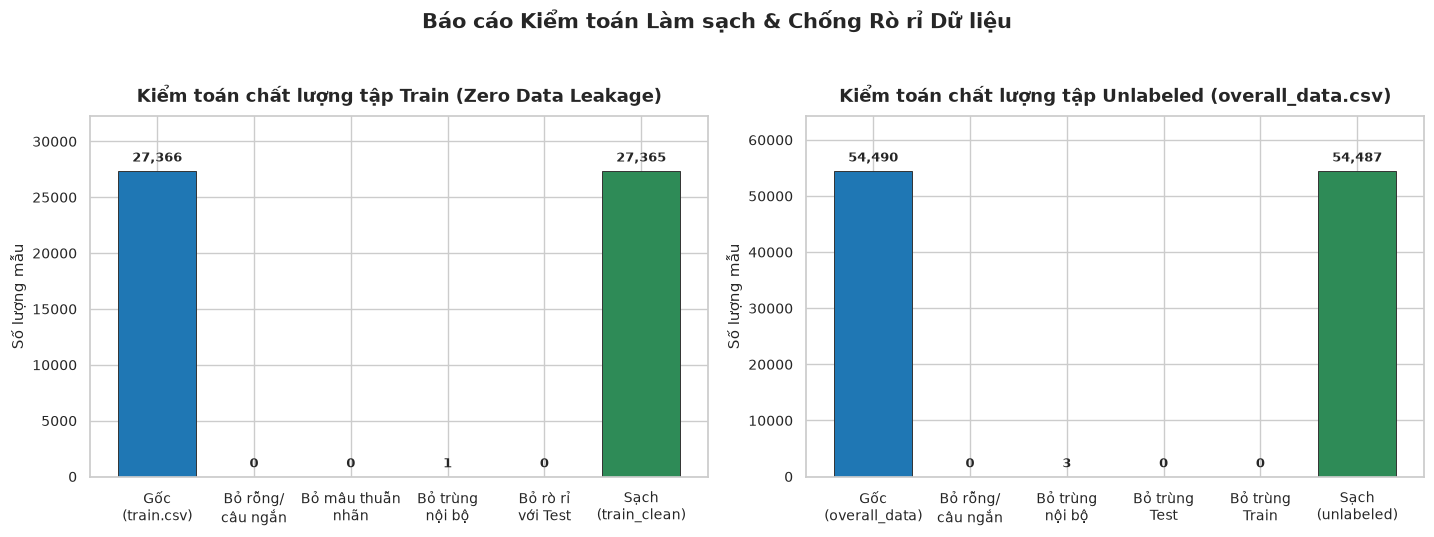

In [8]:
# Bước 2.8 — Biểu đồ B2.5: Kiểm toán làm sạch & chống rò rỉ dữ liệu
fig5 = plot_data_cleaning_audit(
    audit_report=audit_report,
    save_dir=FIG_DIR,
    filename_stem="B2_05_kiem_toan_lam_sach_du_lieu",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

In [9]:
# Bước 2.9: Minh họa sự khác biệt giữa tiền xử lý PhoBERT (tách từ pyvi) và Subword Models
sample_texts = train_pool_df[cfg.text_column].head(3).tolist()
prep_subword = VietnameseESGPreprocessor(use_word_segmenter=False)
prep_phobert = VietnameseESGPreprocessor(use_word_segmenter=True)

print("=== MINH HỌA TIỀN XỬ LÝ ĐỒNG NHẤT ===")
for i, txt in enumerate(sample_texts, start=1):
    print(f"\n[Mẫu {i}]")
    print(f"  - Subword (Vi-ELECTRA/ViSoBERT/...): {prep_subword.segment_text(txt)[:140]}...")
    print(f"  - Word-level (PhoBERT + pyvi)      : {prep_phobert.segment_text(txt)[:140]}...")

print("\n=== DANH SÁCH FILE BIỂU ĐỒ ĐÃ LƯU TẠI B2_eda ===")
for p in sorted(FIG_DIR.glob("*")):
    print(f"  - {p.name}")

=== MINH HỌA TIỀN XỬ LÝ ĐỒNG NHẤT ===

[Mẫu 1]
  - Subword (Vi-ELECTRA/ViSoBERT/...): Ông Lý Quang Diệu từng là người sáng lập kiêm Chủ tịch đầu tiên của Khu Công nghiệp Việt NamSingapore VSIP vào năm 1996...
  - Word-level (PhoBERT + pyvi)      : Ông Lý_Quang_Diệu từng là người sáng_lập kiêm Chủ_tịch đầu_tiên của Khu_Công_nghiệp Việt_NamSingapore VSIP vào năm 1996...

[Mẫu 2]
  - Subword (Vi-ELECTRA/ViSoBERT/...): Nhóm Tiếp cận của chúng tôi được gắn kết trong tổ chức Sản phẩm và Công nghệ của chúng tôi và tập trung vào việc tạo điều kiện cho khách hàn...
  - Word-level (PhoBERT + pyvi)      : Nhóm Tiếp_cận của chúng_tôi được gắn_kết trong tổ_chức Sản_phẩm và Công_nghệ của chúng_tôi và tập_trung vào việc tạo điều_kiện cho khách_hàn...

[Mẫu 3]
  - Subword (Vi-ELECTRA/ViSoBERT/...): Xét về độ tuổi, cấu trúc năm 2023 như sau: từ 18-30 chiếm 38 %, từ 31-40 chiếm 42 %, từ 41-50 chiếm 15%, từ 51-60 chiếm 4% và trên 60 chiếm ...
  - Word-level (PhoBERT + pyvi)      : Xét về độ tuổi , cấu_tr